In [1]:
from ipywidgets import interact, FloatSlider
from IPython.display import display

import matplotlib.pyplot as plt
import numpy as np

import crimper

# Insert here the crimper dimensions and specifications

in this section the user is to insert all the requirements for the crimper

In [56]:
# number of crimp heads

N = 12

# crimper external radious

Rp = 32.7

#crimp head geometry

bd = 17.3
sd = -6
bp = 32.6
sp = -2.6

width = 15
depth = 200

pin_diameter = 4

# total radial crimp force
stent_lenght = 200 #mm
newton_stent_cm = 1.7 # N.cm

F_tot = stent_lenght*0.1*newton_stent_cm
F_per_head = F_tot/N
print(F_per_head)

c = crimper.Crimper(N, Rp, bd, sd, bp, sp, pin_diameter, width, depth)
c.interactive()

2.8333333333333335


interactive(children=(FloatSlider(value=20.0, description='ring angle', max=25.34, min=14.6, step=0.5), Output…

<function crimper.Crimper.interactive.<locals>.draw(delta)>

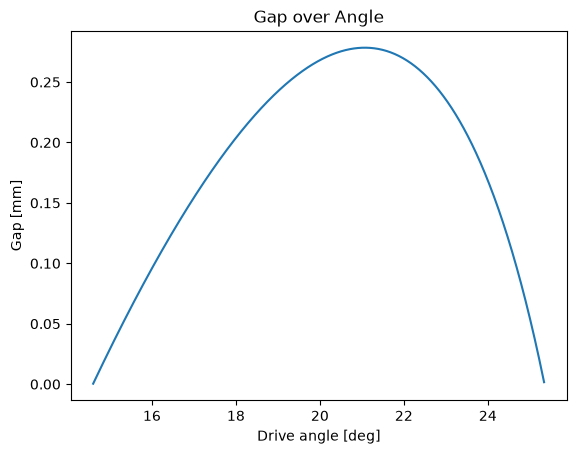

In [57]:
c.plot_gap_over_angle()

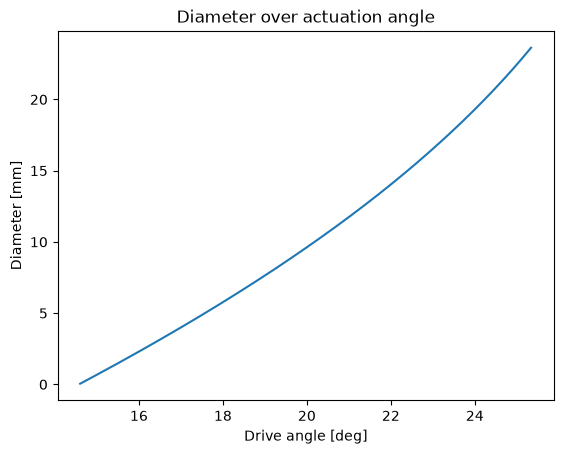

In [58]:
c.plot_diameter_by_angle()

[np.float64(88.83240779285914), np.float64(89.33327628758731), np.float64(89.5749876898183), np.float64(89.71935068908536), np.float64(89.81918913127069), np.float64(89.89584607824224), np.float64(89.95927261873938), np.float64(90.01461332634061), np.float64(90.06474438881438), np.float64(90.11137570281501), np.float64(90.15557546769608), np.float64(90.198038843988), np.float64(90.23923401075872), np.float64(90.27948562180245), np.float64(90.31902454379123), np.float64(90.35801859027228), np.float64(90.39659211785461), np.float64(90.43483886908503), np.float64(90.47283059633673), np.float64(90.51062297929559), np.float64(90.54825976485134), np.float64(90.58577571442605), np.float64(90.62319873576138), np.float64(90.66055144721486), np.float64(90.6978523408608), np.float64(90.73511665781683), np.float64(90.77235705437893), np.float64(90.80958411420667), np.float64(90.84680674591691), np.float64(90.88403249447391), np.float64(90.92126778709378), np.float64(90.95851812893962), np.float64(

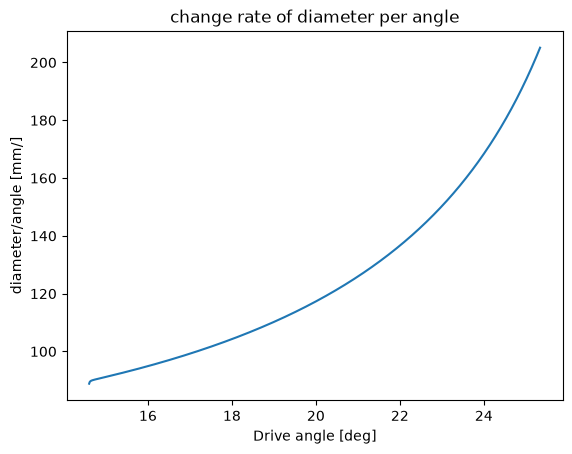

In [59]:
c.plot_rate_of_aperture()

## Motor torque Requirements

In [60]:
stent_lenght = 200 #mm
newton_stent_cm = 4 # N.cm

F_tot = stent_lenght*0.1*newton_stent_cm

F_per_head = F_tot/N

print(f"total Force for stent: {F_tot}N")
print(f"Force per crimp head: {round(F_per_head,3)} N")


print(f"Max Torque at the ring: {round(c.ring_torque(F_per_head)["torque_Nm"],3)} Nm")               # 10 N per tip -> 8.07 N*m at 32.15 deg

c.motor_torque(10.0,1,0.6,1)          # 0.448 N*m at the motor

total Force for stent: 80.0N
Force per crimp head: 6.667 N
Max Torque at the ring: 13.674 Nm


np.float64(20.511521566433224)

## Calculating Pin Forces and diameters

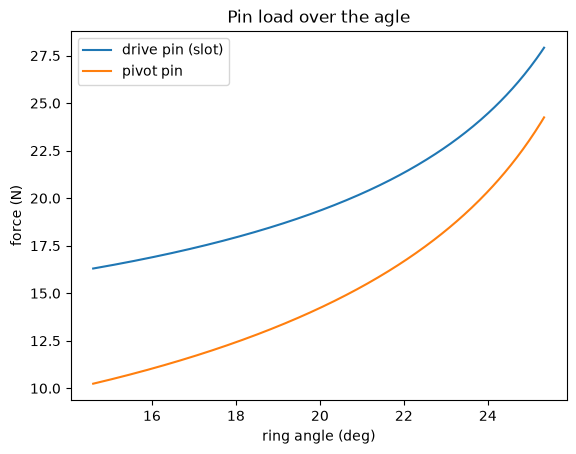

In [61]:
r = c.max_pin_forces(F_per_head)      


plt.plot(r["angles"], r["slot_N"], label="drive pin (slot)")
plt.plot(r["angles"], r["pivot_N"], label="pivot pin")
plt.title("Pin load over the agle")
plt.xlabel("ring angle (deg)"); plt.ylabel("force (N)"); plt.legend(); plt.show()

In [62]:
c.min_pin_diameter(F_per_head,200,2,1,10,8,"cantilever",8)

{'d_min': 1.757922040135698,
 'governed_by': 'bending',
 'checks': {'shear': np.float64(0.3835495903296931),
  'bending': 1.757922040135698,
  'bearing': 0.006666666666666667},
 'M_Nmm': 53.333333333333336,
 'skipped': []}

In [63]:
c.pin_margins()

{'drive': {'angled_face': 1.4538475772933652,
  'far_edge': 7.0,
  'back_end': 16.243,
  'flat_face': 4.0},
 'pivot': {'angled_face': 12.048333950160456,
  'far_edge': 10.4,
  'back_end': 0.9429999999999978,
  'flat_face': 0.6000000000000001}}

In [64]:
c.check_pins(
    F=F_per_head,
    sy_MPa=200,
    safety_factor=3,
    edge_margin_mm=3,
    shear_planes=1,
    bearing_length_mm=10,
    support="cantilever",
    arm_mm=10)

{'drive': {'load_N': np.float64(27.915756847207295),
  'd_min': np.float64(3.4939250986286132),
  'governed_by': 'bending',
  'd_chosen': 4,
  'strength_ok': np.True_,
  'margins_mm': {'angled_face': 1.4538475772933652,
   'far_edge': 7.0,
   'back_end': 16.243,
   'flat_face': 4.0},
  'fit_ok': False,
  'd_max_by_width': 0.9076951545867304},
 'pivot': {'load_N': np.float64(24.25003720098554),
  'd_min': np.float64(3.3337619948160278),
  'governed_by': 'bending',
  'd_chosen': 4,
  'strength_ok': np.True_,
  'margins_mm': {'angled_face': 12.048333950160456,
   'far_edge': 10.4,
   'back_end': 0.9429999999999978,
   'flat_face': 0.6000000000000001},
  'fit_ok': False,
  'd_max_by_width': -0.7999999999999998}}